# **CHAPTER 14 - FILE HANDLING**
----
*Files are named locations on disk to store related information*. Since *Random Access Memory (RAM)* is volatile and loses its data as the computer is turned off, hence files helps in to permanently store data on a storage device like *hard disk*.

## **TYPE OF FILES**
Every file is basically just a series of bytes stored one after the other. There are two type of files that can be managed using Python programs.

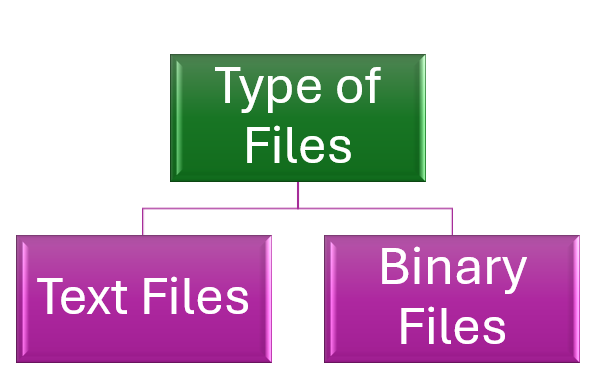


### **TEXT FILES**
These files hold plain text data, sequence of characters consisting of alphabets, numbers and other special symbols. 

- It is a file that stores information in ASCII, UNICODE or any other encoding scheme, the value of each character of the text file is stored as bytes. 
- While opening a text file, the text editor translates each ASCII value and shows us the equivalent character that is readable by the human being.
- Each line of text is terminated with a special character known as *EOL* (End of Line) character or delimiter character. 
- When a text editor or a program interpreter encounters EOL character, it displays the remaining file contents starting from a new line.

In [2]:
# EBCDIC
text = 'This is a text'            # 0100 0001 (65)
bytes = []
for ch in text:
    bytes.append(bin(ord(ch)))

print(bytes)

['0b1010100', '0b1101000', '0b1101001', '0b1110011', '0b100000', '0b1101001', '0b1110011', '0b100000', '0b1100001', '0b100000', '0b1110100', '0b1100101', '0b1111000', '0b1110100']


In [3]:
ch = 0b1000001      # code for letter A
print(f"{chr(ch)}")

A


### **BINARY FILES**

These files are best suited for storing structures or objects. It is a file that contains information in the same format as it is held in memory. In binary files, no delimiters are used for a line and no translations occur here. They represent the actual content such as *image*, *audio*, *video*, *compressed* versions of other files, *executable* files, etc.

## **FILE HANDLING**

File handling in Python refers to the capability of the language to interact with files stored on a computer's disk,
allowing programs to read from and write to these files as needed.

At the most basic level, file handling encompasses operations such as *opening a file*, *reading its content*, *writing new content*, *appending data to an existing file*, and finally *closing the file* to release the system resources associated with it. 

The importance of these operations extends beyond simple tasks; they are central to programs that require data
storage, logging of events, or the processing of large datasets. Many applications, from web servers to local desktop software, rely on file handling to store user preferences, cache information, or log errors.

## **FILE OPERATIONS**
In Python, a file operation takes place in the following order:

1.	Open a file.
2.	Read or write (perform operation).
3.	Close the file.


### **1. OPENING FILE**
A file can be opened in following modes. 

-	**create/overwrite**: Each time a fresh file shall be created. If the named file already exists, its contents shall be overwritten.
-	**read**: Extracts data from the named file and returns error if fails to access file.
-	**append**:  Creates a new file if named file does not exist, otherwise new data are added at the end of the file.

#### `open() Function`

Python provides a built-in `open ()` function to open a file. This function returns a file object also called a handle. The `open ()` function require two mandatory parameters: *filename*, and *mode*.

**Syntax:** 	`file_handle = open (filename[, mode='r']) `

- *file_handle* is the variable that holds the reference to the disk file.
- *filename* is physical address and filename to be opened.
- *mode* tells what kind of operation must carried out on the selected file. Default file mode is read or `r`. 

In [ ]:
# accessing file - same folder as of the application
filename="demo.py"  # no reference to the folder

In [ ]:
# accessing file - some other subfolder under current folder
filename="export\\demo.py"        # \\ path separator for windows OS
filename="export/demo.py"         # / path separator for unix/linux based OS

In [ ]:
# accessing file - stored on some other drive
filename="d:\\Documents\\GuessNumber.pdf"        

In [ ]:
# By default, the file is opened in text mode. The default mode is read-only. The default mode is "rt" which means read text. You can also specify the mode explicitly as "r" or "rt".
# both are same.
file = open("demo.py", "r")    # mode="r"
file = open("demo.py")         # mode="tr"

## **FILE MODES**
There are different modes in which file can be opened.
|Mode|Description|
|---|---|
|r|Opens a file for reading. (default)|
|w|Opens a file for writing. Creates a new file if it does not exist or erase old content of the file if it exists|.
|x|Opens a file for exclusive creation. If the file already exists, the operation fails.|
|a|Opens a file for appending at the end of the file without truncating it. Creates a new file if it does not exist.|
|t|Opens in text mode. (default)|
|b|Opens in binary mode.|
|+| a file for updating (reading and writing)|


The default is *reading in `text` mode*. In this mode, we get strings when reading from the file. On the other hand, binary mode returns bytes.

### **2. CLOSING FILES**
It is necessary to close the file that have been opened for either writing or reading. To close the file in question, call `close ()` method w.r.t the file object as given. Closing a file will free up the resources that were tied with the file. 

- Applying changes made in the file on the disk physically.
- Release all resources allocated to the file.

Syntax: 
```py
fileobj.close ()
```

**Example:**

In [4]:
f = open ("demo.py")          # file opened in read mode
text = f.read()                 # entire file read into variable `text`
f.close ()                      # file closed
print("Total Lines =",len(text.splitlines()))
print("Total words =",len(text.split()))

Total Lines = 32
Total words = 107


#### **2.1 `try...catch`** for file close
> if an exception occurs when we are performing some operation with the file, the code exits without closing the file. A safer way is to use a `try`...`finally` block.

In [5]:
# Error
f = open ("file.txt")          # file opened in read mode
text = f.read()                 # entire file read into variable `text`
f.close ()                      # file closed
print("Total Lines =",len(text.splitlines()))
print("Total words =",len(text.split()))

FileNotFoundError: [Errno 2] No such file or directory: 'file.txt'

In [7]:
try:
    f = open("demo.py")
except:
    print("Error in accessing file")
else:
    text = f.read()                 # entire file read into variable `text`
    print("Total Lines =",len(text.splitlines()))
    print("Total words =",len(text.split()))
finally:
   f.close()

print(f.closed)

Total Lines = 32
Total words = 107
True


#### **2.2 WITH STATEMENT**

> Contextual statement **`with`** statement ensures that the file is closed when the block inside the `with` statement is exited. Using with statement, no need to make an explicit call to the `close ()` method. 

**Syntax:**
```py
with open ("file", 'mode') as file_object:
   # perform file operations
```

In [8]:
with open("demo.py") as f:
    text = f.read()                 # entire file read into variable `text`
    print("Total Lines =",len(text.splitlines()))
    print("Total words =",len(text.split()))
print(f.closed)

Total Lines = 32
Total words = 107
True


### **WRITING TO FILES** 

- To write into a file in Python, file must be opened in 
    - write (`w`)   => Always open the file in overwrite mode
    - append (`a`)  => Open file and move cursor to the end of the file or 
    - exclusive creation (`x`) mode. => Ensures that existing file should not be overwritten

The (w) mode will create file in overwrite mode that is even if the named file exists on the location, it will overwrite its contents without issuing any warning.

#### **1. ` .write ()` method**
- This method  is use to write a string or sequence of bytes (for binary files) in the file object. 
- This method also returns the number of characters written to the file.

**Syntax:**

```py
fileobject.write(data=None)
```

In [9]:
# open file in `w` mode
# file is always created afresh clear all prev data.
file = open("data.txt","w")         # always overwrite mode will be applied
bytes=file.write("This is the first line in the file I have created using python\n")
print(bytes,'bytes written to file')
file.close()

63 bytes written to file


In [10]:
# using with clause
with open("data.txt","w") as file:        # always overwrite mode will be applied
    bytes=file.write("You won't see the data previously stored in this file as it has been overwritten\n")

print(bytes,'written to file')

81 written to file


In [31]:
# open file in `a` mode
# file is created only if it doesnot exist, 
# otherwise new content is added to the end existing file.
file = open("data.txt","a")          
file.write("This is the second line in the file I had created using python\n")
file.close()

In [13]:
# open file in `x` mode
# file is created only if it doesnot exist, 
# otherwise FileExistsError will be raised.
try:
    file = open("kdata.txt","x")         
except FileExistsError:
    print("Illegal File Operation: Changes are not allowed on existing file")
else:
    file.write("This is operation is not possible\n")
finally:
    file.close()

#### 2. **.writelines () method**  
This method is use to write a list of strings or sequence in the file object. The sequence can be any iterable object producing strings, typically a list of strings. This method returns nothing.

**Syntax:**

```py
fileobject.writelines(iterator)
```
Example: 

In [14]:
f = open ("test.txt", "w")
slist = ["This is the first line in the text file.\n", 
         "This is the second line in the text file.\n",
         "This is the third line in the text file."
         ]
f.writelines (slist)
f.close ()

### **READING FILES**
To read a file in Python, open the file in reading `r` mode. Python provides various methods available for fetching data from the file purpose. 

#### **1. .read (size) method**
Reads size characters from the file. If the size parameter is not specified, it reads and returns up to the end of the file.

**Syntax:**
```python
container = fileobject.read(size=None)
```
- size parameter specifies no of bytes to read. If omitted entire file is read.
- after read size bytes, cursor moves to the next character in the file.

In [15]:
file = open('demo.py','r')
f50char = file.read(50)     # returns first 50 characters and move cursor
                            # to 11th character
print(f50char)
# .tell() returns current cursor position in the file.
print("Current position:",file.tell()) 
nxt50 = file.read(50)
print(nxt50)
print("Current position:",file.tell()) 

import math

def is_prime(n: int) -> bool:
	"""Ret
Current position: 53
urn True if n is a prime number, otherwise False."
Current position: 103


In [16]:
# read remaining content
rem = file.read()
print(rem)
print("Current position:",file.tell()) 
file.close()

""
	if n <= 1:
		return False
	if n <= 3:
		return True
	if n % 2 == 0:
		return False
	r = int(math.isqrt(n))
	for i in range(3, r + 1, 2):
		if n % i == 0:
			return False
	return True


def main():
	try:
		s = input("Enter an integer (or comma-separated integers): ")
		parts = [p.strip() for p in s.split(",") if p.strip()]
		nums = [int(p) for p in parts]
	except Exception:
		print("Invalid input")
		return

	for n in nums:
		print(f"{n}: {'prime' if is_prime(n) else 'not prime'}")


if __name__ == "__main__":
	main()

Current position: 659


#### **2. .readline (n=-1) method**
The `readline ()` method reads and returns one line from the file. 

**Syntax:**
```python
container = fileobject.readline(size=None)
```
- if size is specified reads in at most size bytes. 
- This method reads a file till the newline, including the newline character.
- if omitted, entire line from current position till end of the line

In [24]:
file = open("demo.py")
line = file.readline()
print(line)
file.close()

import math



#### **3. USING A FOR LOOP**
A file can also be read line-by-line using a for loop. This is both efficient and fast.

**Syntax:**
```python
for line in file:
    # to-do
```

In [26]:
# read entire file using for statement method 
file = open("demo.py")
for line in file:
    print(line,end='')
file.close()

import math

def is_prime(n: int) -> bool:
	"""Return True if n is a prime number, otherwise False."""
	if n <= 1:
		return False
	if n <= 3:
		return True
	if n % 2 == 0:
		return False
	r = int(math.isqrt(n))
	for i in range(3, r + 1, 2):
		if n % i == 0:
			return False
	return True


def main():
	try:
		s = input("Enter an integer (or comma-separated integers): ")
		parts = [p.strip() for p in s.split(",") if p.strip()]
		nums = [int(p) for p in parts]
	except Exception:
		print("Invalid input")
		return

	for n in nums:
		print(f"{n}: {'prime' if is_prime(n) else 'not prime'}")


if __name__ == "__main__":
	main()


#### **4. .readlines () method**
The `readlines ()` method returns a list of lines of the entire file.

**Syntax:**
```python
container = fileobject.readlines()
```

In [28]:
file = open("test.txt")
lines = file.readlines()
file.close()
print("File contains",len(lines),'lines.')
print("-"*80)
print(lines)

File contains 3 lines.
--------------------------------------------------------------------------------
['This is the first line in the text file.\n', 'This is the second line in the text file.\n', 'This is the third line in the text file.']


### **APPENDING IN THE FILE**

Append means adding new content to the existing file. In order to open the file in append mode, use either '`a`' or '`a+`' as the access mode. 

The file opened in mode ‘`a`' is created, if the specified file does not exists,  otherwise the file handle is positioned at the end of the file. Hence, the data being written is inserted after the existing data.

The mode ‘`a+`' open the file in both read and write mode. Rest works same as ‘`a`' mode



In [29]:
# append
file = open("test.txt",'a')
file.write("\nThis is the fourth line in the file.")
file.close()

# read
file = open("test.txt")
print(file.read())
file.close()

This is the first line in the text file.
This is the second line in the text file.
This is the third line in the text file.
This is the fourth line in the file.


In [30]:
# write a program to copy the content in other file
infile = open("test.txt","r")
outfile = open("copytest.txt","w")

for line in infile:
    outfile.write(line)

# close files
infile.close()
outfile.close()

In [ ]:
infile = open("test.txt","r")
outfile = open("copy.txt","w")

outfile.writelines(infile.readlines())

# close files
infile.close()
outfile.close()

In [ ]:
infile = open("test.txt","r")
outfile = open("copy.txt","w")

outfile.write(infile.read())

# close files
infile.close()
outfile.close()

In [ ]:
# The following example shows a complete script that reads data, transforms it, and writes the output:

# Step: End-to-end example of file processing
input_filename = 'raw_data.txt'
output_filename = 'processed_data.txt'

# Creating a sample input file
with open(input_filename, 'w') as infile:
    infile.write("line one: raw data\n")
    infile.write("line two: raw data\n")
    infile.write("line three: raw data\n")

# Process the input file and write output
with open(input_filename, 'r') as infile, open(output_filename, 'w') as outfile:
    for line in infile:
        # Apply a simple transformation: convert text to uppercase
        transformed_line = line.upper()
        outfile.write(transformed_line)

# Verification: Read the processed file and display its contents
with open(output_filename, 'r') as outfile:
    processed_content = outfile.read()
    print("Processed File Content:")
    print(processed_content)

## **FILE CURSOR POSITION METHODS**
Python provide two methods are used to set or get the current file cursor position (which defines from where the data has to be read or written in the file). Let us take a closer look to the following methods

#### 1. **.tell() method**
The `.tell ()` method returns current position (in number of bytes). This method takes no parameters and returns an integer value. Initially file pointer points to the beginning of the file.

**Syntax:**
```py
file.tell()
```

In [32]:
# tell example
file = open("demo.py","r")
curpos = file.tell()            # positon of cursor in the file
print(f"Current cursor position: {curpos}")
print("Reading first 50 characters:")
print(file.read(50))
curpos = file.tell()            # position after reading first 50 characters
print(f"Current cursor position: {curpos}")
print("Reading next 78 characters:")
print(file.read(78))
curpos = file.tell()
print(f"Current cursor position: {curpos}")
file.close()

Current cursor position: 0
Reading first 50 characters:
import math

def is_prime(n: int) -> bool:
	"""Ret
Current cursor position: 53
Reading next 78 characters:
urn True if n is a prime number, otherwise False."""
	if n <= 1:
		return Fals
Current cursor position: 133


#### 2. **.seek() method**
The `seek ()` change current file cursor position to specific position (where the data has to be read or written in the file). 

**Syntax:** 	
```py
f.seek(offset [,whence={0|1|2}])
```
- offset: The number of bytes to move the pointer.
- whence (Optional): The reference point from which the offset is applied:
    - 0 (default): Absolute positioning from the beginning of the file.
    - 1: Positioning relative to the current pointer position.
    - 2: Positioning relative to the end of the file. 

##### **Mode Restrictions:**
- In *Text Mode* ('r', 'w'), you can generally only seek from the beginning (whence=0). Relative seeks from the current or end positions often raise an `io.UnsupportedOperation`.
- In Binary Mode ('rb', 'wb'), all three whence values are supported.
- In append mode ('a' or 'a+'), any manual .seek() operation will be overridden, and the pointer will move back to the end of the file as soon as a write occurs

In [33]:
# seek example
file = open("demo.py","r")
curpos = file.tell()            # positon of cursor in the file
print(f"Current cursor position: {curpos}")
print("Reading first 50 characters:")
print(file.read(50))
# jump to 250th byte and read next 150 characters
file.seek(250)
print("Reading 150 characters from position:",file.tell())
print(file.read(150))
curpos = file.tell()            # positon of cursor in the file
print(f"Current cursor position: {curpos}")
file.close()

Current cursor position: 0
Reading first 50 characters:
import math

def is_prime(n: int) -> bool:
	"""Ret
Reading 150 characters from position: 250
:
		if n % i == 0:
			return False
	return True


def main():
	try:
		s = input("Enter an integer (or comma-separated integers): ")
		parts = [p.strip
Current cursor position: 409


In [34]:
# Exception for negative seek in text mode
with open("demo.py","r") as file:
    # move to 50th byte
    file.seek(50)
    # read next 50 characters
    print(file.read(50))
    # exception back tracking
    try:
        # move 25 bytes backward w.r.t the current cursor position
        file.seek(-25,1)
        print(file.read(50))
    except IOError as e:
        print("Error:",e)

Return True if n is a prime number, otherwise Fals
Error: can't do nonzero cur-relative seeks


In [35]:
# Exception while seek in append mode
try:
    file = open("files.txt","a")        # by default cursor is positioned at EOF
    file.seek(50)
    file.write("Hello World\n")
except IOError as e:
    print ("Error:",e)
finally:
    file.close()

## **BINARY FILE OPERATIONS**
-----

- Binary files are best suited for storing non-textual data structures or objects. It is a file that contains information in the same format as it is held in memory

- Unlike text files, binary files do not use character encoding and data are stored as a sequence of bytes, without any transformation. Even a single bit change can corrupt the file and make it unreadable to the supporting application. 

- Also, it is difficult to remove any error which may occur in the binary file.

- These files are not human readable. Thus, trying to open a binary file using a text editor will show garbage values.

### **Serialization and De-serialization**

- **Serialization** or **pickling** is the process of transforming data or an object in memory (RAM) into a stream of bytes called byte streams. These byte streams can then be stored in a disk as binary file or in a database or sent through a network. 

- **De-serialization** or **unpickling** is the inverse of pickling process where a byte stream is converted back to Python object.


### **THE PICKLE MODULE**

The `pickle` module deals with binary files. The module pickle is used for serializing and de-serializing any Python object structure. 

Here, data are not written but *dumped* and similarly, data are not read but *loaded*. 

The `pickle` module must be imported to load and dump data. 

The `pickle` module provides two methods - *`dump()`* and *`load()`* to work with binary files for pickling and unpickling, respectively

### **THE DUMP () METHOD**
This **`dump()`** method converts Python objects for writing data in a binary file. 

Syntax:
```py
dump(dataobject, fileobject)
```
- dataobject is the object that has to be dumped 
- fileobject refers to as a file handle of the binary file.


In [37]:
import pickle as pk
file = open("emp.db","ab")
rec1 = {
    'name': 'Ram',
    'age': 45,
    'job':'Sr. Manager',
    'hometown': 'Una',
    'salary':25000.00
}

rec2 = {
    'name': 'Krishan',
    'age': 50,
    'job':'CEO',
    'hometown': 'Una',
    'salary':35000.00
}

pk.dump(rec1,file)
pk.dump(rec2,file)

file.close()

### **THE LOAD() METHOD**
The *`load()`*  method is used to load (unpickling) data from a binary file. The file to be loaded is opened in binary read (`rb`) mode. 

**Syntax:**
```py
object = load(fileobject)
```
The pickled Python object is loaded from the file having a file handle named `fileobject` and is stored in a `object`. 


In [39]:
import pickle as pk
file = open('emp.db','rb')
print("File No:",file.fileno)
frec = pk.load(file)
print(frec)
frec = pk.load(file)
print(frec)

file.close()

File No: <built-in method fileno of _io.BufferedReader object at 0x00000228ED11CB40>
{'name': 'Ram', 'age': 45, 'job': 'Sr. Manager', 'hometown': 'Una', 'salary': 25000.0}
{'name': 'Krishan', 'age': 50, 'job': 'CEO', 'hometown': 'Una', 'salary': 35000.0}


In [42]:
# File Misc. Methods
file = open("files.txt","w+")
print("Interactive:",file.isatty())
print("Readable:",file.readable())
print("Writable:",file.writable())
print("Seekable:",file.seekable())

Interactive: False
Readable: True
Writable: True
Seekable: True


## **OS Module**

The `os` module is a built-in Python library that provides a portable way of using operating system-dependent functionality. It serves as a bridge between your Python code and the underlying operating system (Windows, macOS, or Linux), allowing you to automate system-level tasks.

### **Its functions:**
- **File and Directory Management:** Create, delete, move, and rename files or folders.
- **Environment Variables:** Access and modify system environment variables.
- **Process Management:** Execute shell commands, manage process IDs (PIDs), and terminate running processes.
- **Path Manipulation:** Handle file paths safely across different operating systems using the `os.path` submodule. 

### **Common Methods**

|Method 	|Description|
|-------|-------|
|`os.getcwd()`	|Returns the Current Working Directory as a string.|
|`os.chdir(path)`	|Changes the directory to the specified path.|
|`os.listdir(path)`	|Returns a list of files and folders in the given directory.|
|`os.mkdir(path)`	|Creates a new directory; raises an error if it already exists.|
|`os.remove(path)`	|Deletes a file.|
|`os.rename(old, new)`	|Renames a file or directory.|
|`os.environ`	|A dictionary-like object providing access to environment variables.|
|`os.system(command)`	|Executes a shell command in a subshell.|

In [43]:
# current working directory
import os
print(os.getcwd())  

d:\OneDrive\O-Level Lectures Notes\python lectures


In [46]:
# make folder
# . -> current path
# .. -> Parent Folder
# / -> Root Folder
# os.makedirs("archive")
os.listdir("/") 

['$RECYCLE.BIN',
 'Documents',
 'OneDrive',
 'OneDriveTemp',
 'System Volume Information']

In [47]:
# change folder 
os.chdir("export")
# create file in the folder
with open('notes.txt','w') as fl:
    fl.write('Hello world!')

In [48]:
print(os.getcwd())  

d:\OneDrive\O-Level Lectures Notes\python lectures\export


In [49]:
# change folder to prev level
os.chdir("..")
print(os.getcwd())

d:\OneDrive\O-Level Lectures Notes\python lectures


In [50]:
# change folder to Python Lectures
os.chdir("../..")
print(os.getcwd())

d:\OneDrive


In [51]:
# change folder to root folder
os.chdir("\\")
print(os.getcwd())

d:\


In [58]:
# back to home
os.chdir("D:/OneDrive/O-Level Lectures Notes/python lectures")
print(os.getcwd())

D:\OneDrive\O-Level Lectures Notes\python lectures


In [55]:
# create a folder name "backup", move to folder and create a text file with two lines
# creating a folder
os.mkdir("backup")
# move to the folder
os.chdir("backup")

# create a file
file = open("trial.txt","w")
file.write("Line 1: Hello to all of you.\n")
file.write("Line 2: Have nice day")
file.close()


In [56]:
# show files
os.chdir("..")
os.listdir()        # show all files and folder in CWD

['.ipynb_checkpoints',
 '.venv',
 'archive',
 'Array Module.ipynb',
 'backup',
 'CH 7 Functions.ipynb',
 'CH 7.1 UDF.ipynb',
 'CH 7.2 Inner Funcions.ipynb',
 'Ch1 Basic Concepts Part 1.ipynb',
 'Ch1 Basic Concepts Part 2.ipynb',
 'CH10 Sets.html',
 'CH10 Sets.ipynb',
 'CH11 Dictionary.html',
 'CH11 Dictionary.ipynb',
 'CH12 ExceptionHandling.html',
 'CH12 ExceptionHandling.ipynb',
 'CH13 File Handling.ipynb',
 'CH14 Numpy.ipynb',
 'CH2 Data Handling.ipynb',
 'CH2.1 Operators.ipynb',
 'CH3 Input Output.ipynb',
 'CH4 Flow of Control.ipynb',
 'CH5 Decision Construct.ipynb',
 'CH6 Loop Constructs.ipynb',
 'CH8 List.ipynb',
 'CH9 Tuples.html',
 'CH9 Tuples.ipynb',
 'copytest.txt',
 'da.ipynb',
 'data.txt',
 'datatypes.png',
 'demo.db',
 'demo.py',
 'edata.txt',
 'emp.db',
 'export',
 'files.txt',
 'images',
 'kdata.txt',
 'my_array.npy',
 'my_array.txt',
 'numpy.ipynb',
 'processed_data.txt',
 'python_strings.ipynb',
 'requirements.txt',
 'test.txt',
 'text.txt']

In [54]:
path = "D:/documents"
files = os.listdir(path)
print(files)

['Contacts', 'Desktop', 'desktop.ini', 'Downloads', 'Favorites', 'Links', 'Music', 'Pictures', 'Saved Games', 'Searches', 'Videos']


In [59]:
# change file name
os.rename("files.txt","file.txt")

In [60]:
os.getcwd()
os.listdir()

['.ipynb_checkpoints',
 '.venv',
 'archive',
 'Array Module.ipynb',
 'backup',
 'CH 7 Functions.ipynb',
 'CH 7.1 UDF.ipynb',
 'CH 7.2 Inner Funcions.ipynb',
 'Ch1 Basic Concepts Part 1.ipynb',
 'Ch1 Basic Concepts Part 2.ipynb',
 'CH10 Sets.html',
 'CH10 Sets.ipynb',
 'CH11 Dictionary.html',
 'CH11 Dictionary.ipynb',
 'CH12 ExceptionHandling.html',
 'CH12 ExceptionHandling.ipynb',
 'CH13 File Handling.ipynb',
 'CH14 Numpy.ipynb',
 'CH2 Data Handling.ipynb',
 'CH2.1 Operators.ipynb',
 'CH3 Input Output.ipynb',
 'CH4 Flow of Control.ipynb',
 'CH5 Decision Construct.ipynb',
 'CH6 Loop Constructs.ipynb',
 'CH8 List.ipynb',
 'CH9 Tuples.html',
 'CH9 Tuples.ipynb',
 'copytest.txt',
 'da.ipynb',
 'data.txt',
 'datatypes.png',
 'demo.db',
 'demo.py',
 'edata.txt',
 'emp.db',
 'export',
 'file.txt',
 'images',
 'kdata.txt',
 'my_array.npy',
 'my_array.txt',
 'numpy.ipynb',
 'processed_data.txt',
 'python_strings.ipynb',
 'requirements.txt',
 'test.txt',
 'text.txt']

In [ ]:
os.rename('test.txt','text.txt')

In [61]:
# delete file
os.remove("test.txt")

In [62]:
# File details
filedetails = os.stat("demo.py")
print("File Size:",filedetails.st_size,"bytes")
print("File Mode:",filedetails.st_mode)

File Size: 659 bytes
File Mode: 33206
